In [1]:
import mrcfile, numpy as np

In [13]:
from quantem.tomography.tomography_lite import TomographyLiteConv, TomographyLiteINR
from quantem.tomography.object_models import ObjConstraintParams
from quantem.tomography.dataset_models import DatasetConstraintParams
from quantem.core.visualization import show_2d

from quantem.core.utils.tomography_utils import fourier_binning

device = "cpu" # Set device

In [ ]:
d = r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP\tomo108"

stack = mrcfile.read(d + r"\tomo200528_108.st").astype(np.float32)
angles = np.loadtxt(d + r"\tomo200528_108.rawtlt")
order = np.argsort(angles)
stack, angles = stack[order], angles[order]
n_box = 256//2
n, x, y = stack.shape
reshape_stack = stack[:, x//2-n_box:x//2+n_box, y//2-n_box:y//2+n_box]

(35, 256, 256)

In [32]:
b = 2
n, ny, nx = reshape_stack.shape
stack_b = stack[:, :ny//b*b, :nx//b*b].reshape(n, ny//b, b, nx//b, b).mean(axis=(2, 4))
stack_b = (stack_b - stack_b.mean(axis=(1, 2), keepdims=True)) / stack_b.std(axis=(1, 2), keepdims=True)
print(stack_b.shape)  # aim for about 128 px per side

(35, 128, 128)


In [35]:
tomo = TomographyLiteConv.from_dataset(
    tilt_series = stack_b,
    tilt_angles = angles,
    device = device
)

sirt Reconstruction | Loss: 1.6356:   6%|▌         | 6/100 [00:14<03:39,  2.33s/it]

Relaxation parameter changed to: 0.2125


sirt Reconstruction | Loss: 1.6440:  17%|█▋        | 17/100 [00:40<03:16,  2.37s/it]

Relaxation parameter changed to: 0.18062499999999998


sirt Reconstruction | Loss: 1.6468:  28%|██▊       | 28/100 [01:05<02:49,  2.35s/it]

...

sirt Reconstruction | Loss: 1.6500:  83%|████████▎ | 83/100 [03:11<00:38,  2.29s/it]

Relaxation parameter changed to: 0.0681226312597656


sirt Reconstruction | Loss: 1.6502:  94%|█████████▍| 94/100 [03:38<00:14,  2.42s/it]

Relaxation parameter changed to: 0.05790423657080076


sirt Reconstruction | Loss: 1.6503: 100%|██████████| 100/100 [03:53<00:00,  2.34s/it]


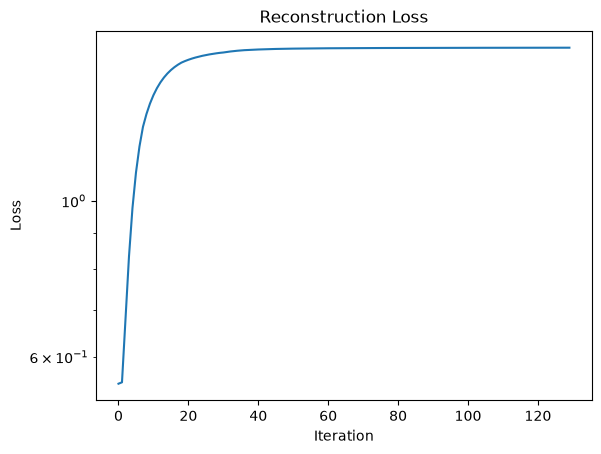

In [38]:
tomo.reconstruct(
    num_iter = 100,
    mode = "sirt",
    inline_alignment = True,
    smoothing_sigma = 0.1,
    show_metrics = True
)

(<Figure size 1200x400 with 3 Axes>,
 array([<Axes: title={'center': 'Conventional Reconstruction Summed X'}>,
        <Axes: title={'center': 'Conventional Reconstruction Summed Y'}>,
        <Axes: title={'center': 'Conventional Reconstruction Summed Z'}>],
       dtype=object))

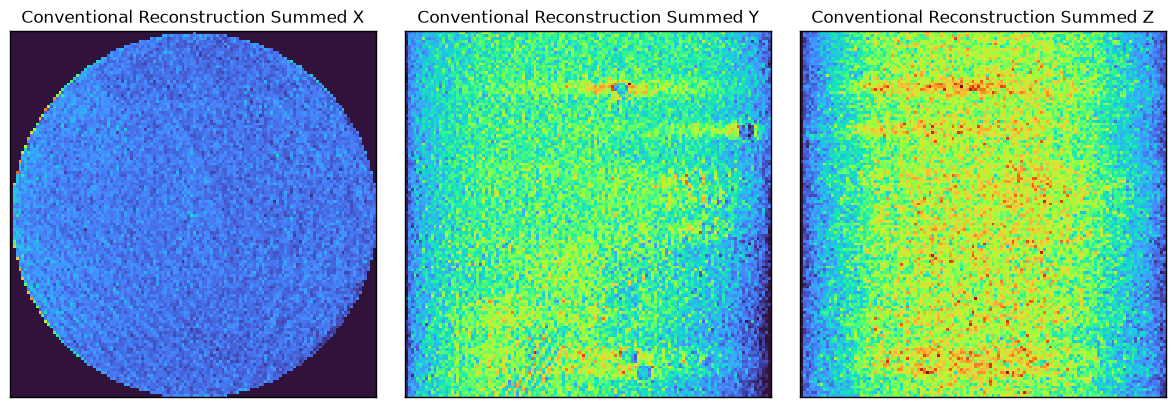

In [39]:
obj_conv = tomo.obj_model.obj.detach().cpu().numpy()
show_2d(
    [obj_conv.sum(axis = 0), obj_conv.sum(axis = 1), obj_conv.sum(axis = 2)],
    title = ['Conventional Reconstruction Summed X', 'Conventional Reconstruction Summed Y', 'Conventional Reconstruction Summed Z'],
    cmap = 'turbo',
    vmin = 0,
    vmax = None,
)

## INR

In [43]:
log_d = r"C:\Users\ruben\OneDrive - Delft University of Technology\Documenten\Nanobiology 6\ARP"


tomo_inr = TomographyLiteINR.from_dataset(
    tilt_series = stack_b,
    tilt_angles = angles,
    device = device,
    log_dir = log_d
)

Model built, compiled successfully
Setting up DDP for obj_model


In [45]:
obj_constraints = ObjConstraintParams.ObjINRConstraints(
    positivity=True,
    tv_vol=1e-4,
    sparsity=1e-6,
)

dset_constraints = DatasetConstraintParams.BaseTomographyDatasetConstraints(
    tv_zs = 1e-6,
    tv_shifts = 1e-6,
)

# First iteration of the reconstruct call will be slow due to @torch.compile.
# Subsequent calls will be faster.
tomo_inr.reconstruct(
    num_iter = 30,
    # reset = True,
    obj_lr = 5e-5,
    pose_lr = 1e-2,
    batch_size = 1024,
    num_workers = 0,
    learn_pose = True,
    scheduler_type = "cosine_annealing",
    obj_constraints = obj_constraints,
    dset_constraints = dset_constraints,
    show_metrics = True,
)

  0%|          | 0/30 [13:45<?, ?it/s]


KeyboardInterrupt: 